## Homework 6

In [76]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt

### Part 1: Practice resampling & chart building with Pandas and Matplotlib

In [77]:
# For this assignment, you'll be working with NYC payroll data again. 
# Import it from wherever you stored the data

payroll_data = pd.read_csv('../input/Citywide_Payroll_Data__Fiscal_Year__20240616.csv')
print(len(payroll_data))

552938


Using this data, create an ordered, horizontal bar chart of the top 10 biggest agencies in NYC. 

In [78]:
payroll_data.head()

,Fiscal Year,Payroll Number,Agency Name,Last Name,First Name,Mid Init,Agency Start Date,Work Location Borough,Title Description,Leave Status as of June 30,Base Salary,Pay Basis,Regular Hours,Regular Gross Paid,OT Hours,Total OT Paid,Total Other Pay
0,2023,67,ADMIN FOR CHILDREN'S SVCS,ROODE,SELENA,R,07/22/2019,BRONX,CHILD PROTECTIVE SPECIALIST,ACTIVE,65921.0,per Annum,1820.0,65977.23,6.50,244.34,4400.66
1,2023,67,ADMIN FOR CHILDREN'S SVCS,AARON,TERESA,NaN,03/21/2016,BRONX,CHILD PROTECTIVE SPECIALIST,ACTIVE,65921.0,per Annum,1820.0,65998.30,448.00,22072.10,15938.80
2,2023,67,ADMIN FOR CHILDREN'S SVCS,AARONS,CAMELIA,M,08/08/2016,BROOKLYN,CHILD PROTECTIVE SPECIALIST,ON LEAVE,65921.0,per Annum,602.0,23163.11,28.75,1295.17,8994.61
3,2023,67,ADMIN FOR CHILDREN'S SVCS,ABBASSI,MARIAM,N,11/21/2022,QUEENS,CHILD PROTECTIVE SPECIALIST,ACTIVE,55463.0,per Annum,1050.0,31082.77,27.75,928.43,3115.50
4,2023,67,ADMIN FOR CHILDREN'S SVCS,ABDEL WEDOUD,LASHAWN,NaN,04/24/2023,BROOKLYN,YOUTH DEVELOPMENT SPECIALIST,ACTIVE,50001.0,per Annum,280.0,7792.26,0.00,0.00,0.00


In [79]:
# Your code here.
top10 = payroll_data['Agency Name'].value_counts().head(10).reset_index()
top10.head(10)

,Agency Name,count
0,DEPT OF ED PEDAGOGICAL,106882
1,DEPT OF ED PER SESSION TEACHER,82883
2,POLICE DEPARTMENT,58617
3,DEPT OF ED PARA PROFESSIONALS,39580
4,BOARD OF ELECTION POLL WORKERS,29915
5,DEPT OF ED HRLY SUPPORT STAFF,26900
6,FIRE DEPARTMENT,19072
7,DEPARTMENT OF EDUCATION ADMIN,17551
8,DEPT OF PARKS & RECREATION,16732
9,DEPT OF ED PER DIEM TEACHERS,15020


<Axes: ylabel='Agency Name'>

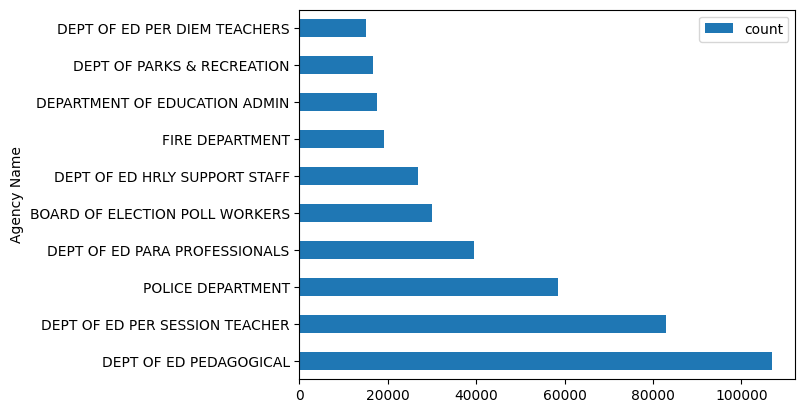

In [80]:
top10.plot(kind="barh", x="Agency Name", y="count")

Now, create an ordered, horizontal bar chart of the top ten agencies with the highest median base salary.

In [81]:
# Your code here.

top10_salary = payroll_data.groupby("Agency Name")["Base Salary"].median().sort_values(
    ascending=False
).head(10).reset_index(name="median_base_salary")

top10_salary

,Agency Name,median_base_salary
0,OFFICE OF COLLECTIVE BARGAININ,140000.0
1,FINANCIAL INFO SVCS AGENCY,126952.0
2,BRONX COMMUNITY BOARD #12,115307.0
3,MUNICIPAL WATER FIN AUTHORITY,112604.0
4,DISTRICTING COMMISSION,103750.0
5,DEPT OF ED PEDAGOGICAL,101441.0
6,OFFICE OF THE ACTUARY,101425.0
7,BROOKLYN COMMUNITY BOARD #8,101322.5
8,INDEPENDENT BUDGET OFFICE,99703.5
9,BRONX COMMUNITY BOARD #3,98748.0


<Axes: ylabel='Agency Name'>

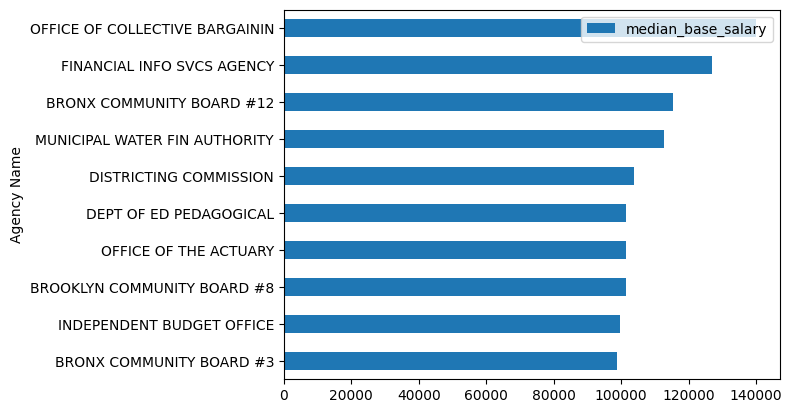

In [82]:
top10_salary.sort_values("median_base_salary", ascending=True).plot(
    kind="barh",
    x="Agency Name",
    y="median_base_salary"
)

Let's return to our police data to practice resampling. 

In [83]:
# Remember to change the file path to match where your data is stored. 

police_data = pd.read_csv("../input/fatal-police-shootings-data 2.csv", parse_dates=["date"])
len(police_data)

10430

Remember in class, we learned that resampling requires several basic steps:

1. Make sure that Pandas is reading in your date column as a date. If it's not, convert it to datetime.
2. Create a new dataframe with your date column as your index
3. Resample the data over the time interval of your choosing.

With this in mind, resample the data over a monthly period and plot it in a line chart.

In [84]:
# Your code here.

police_data.dtypes

police_data_new = police_data.set_index("date")

<Axes: xlabel='date'>

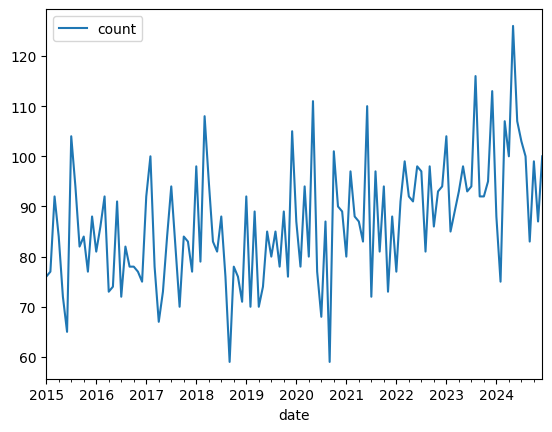

In [85]:
police_data_resampled = police_data_new.resample("ME").size().reset_index(name="count")

police_data_resampled.plot(x="date", y="count", kind="line")

Now create an ordered bar chart of total police killings by year. Put the two charts side by side using the strategy we reviewed in class.

In [86]:
# Total police killings by year
police_killings_by_year = (
    police_data_new
    .resample("YE")
    .size()
    .reset_index(name="count")
)

police_killings_by_year["year"] = police_killings_by_year["date"].dt.year
police_killings_by_year

,date,count,year
0,2015-12-31,995,2015
1,2016-12-31,959,2016
2,2017-12-31,984,2017
3,2018-12-31,992,2018
4,2019-12-31,993,2019
5,2020-12-31,1021,2020
6,2021-12-31,1050,2021
7,2022-12-31,1097,2022
8,2023-12-31,1164,2023
9,2024-12-31,1175,2024


<BarContainer object of 10 artists>

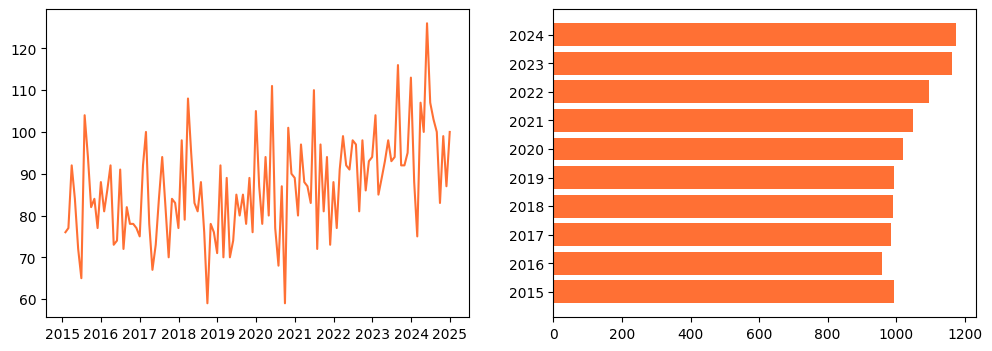

In [87]:
fig, ax = plt.subplots(1,2)
fig.set_size_inches(12,4)

ax[0].plot(police_data_resampled["date"], police_data_resampled["count"], color="#ff7034")
ax[1].barh(police_killings_by_year["year"].astype(str), police_killings_by_year["count"], color="#ff7034")

### Part 2: Assignment 1

Come to class having made significant progress on your first assignment. Please come prepared to share your progress with your classmates and ask them/me any questions you might have for feedback. Part of classtime will be devoted to working on your original data analysis.